In [6]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, confusion_matrix
)

# Cấu hình giao diện biểu đồ
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (6, 5)
print("-> Đã nạp thành công các thư viện huấn luyện.")

-> Đã nạp thành công các thư viện huấn luyện.


In [7]:
# Đường dẫn tới file dữ liệu sạch đã xử lý từ Giai đoạn 1
data_path = 'data/processed/data_clean.csv'
if not os.path.exists(data_path):
    data_path = '../data/processed/data_clean.csv'

df = pd.read_csv(data_path)
print(f"Kích thước tập dữ liệu: {df.shape} dòng, {df.shape} cột")

# Tách đặc trưng đầu vào (X) và nhãn mục tiêu (y)
X = df.drop(columns=['Outcome'])
y = df['Outcome']
print(f"Danh sách thuộc tính đầu vào: {list(X.columns)}")

Kích thước tập dữ liệu: (768, 9) dòng, (768, 9) cột
Danh sách thuộc tính đầu vào: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


In [8]:
# Phân chia dữ liệu với stratify=y để giữ tỷ lệ phân bố nhãn đều
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Tập Train ban đầu : {X_train.shape} mẫu (Tỷ lệ lớp 1: {y_train.mean():.2%})")
print(f"Tập Test độc lập  : {X_test.shape} mẫu (Tỷ lệ lớp 1: {y_test.mean():.2%})")

Tập Train ban đầu : (614, 8) mẫu (Tỷ lệ lớp 1: 34.85%)
Tập Test độc lập  : (154, 8) mẫu (Tỷ lệ lớp 1: 35.06%)


In [9]:
# 1. Áp dụng SMOTE chỉ trên tập Train để tránh rò rỉ dữ liệu (Data Leakage)
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

# 2. Chuẩn hóa thang đo bằng StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)

print(f"Tập Train sau khi cân bằng SMOTE: {X_train_res.shape} mẫu")
print(f"Tỷ lệ nhãn sau SMOTE: Lớp 0 = {(y_train_res==0).sum()}, Lớp 1 = {(y_train_res==1).sum()}")

Tập Train sau khi cân bằng SMOTE: (800, 8) mẫu
Tỷ lệ nhãn sau SMOTE: Lớp 0 = 400, Lớp 1 = 400


In [11]:
# Khai báo không gian tìm kiếm siêu tham số cho các mô hình
models = {
    'LogisticRegression': (
        LogisticRegression(random_state=42),
        {'C': [0.01, 0.1, 1, 10]}
    ),
    'RandomForest': (
        RandomForestClassifier(random_state=42),
        {'n_estimators': [50, 100, 200], 'max_depth': [3, 5, 7, None]}
    ),
    'XGBoost': (
        XGBClassifier(random_state=42, eval_metric='logloss'),
        {'n_estimators': [50, 100, 200], 'max_depth': [3, 5, 7], 'learning_rate': [0.01, 0.1]}
    )
}

results = []
best_model = None
best_recall = 0
best_name = ""

# Thực nghiệm huấn luyện và đánh giá ưu tiên chỉ số Recall
for name, (model, params) in models.items():
    grid = GridSearchCV(model, params, scoring='recall', cv=5, n_jobs=-1)
    grid.fit(X_train_scaled, y_train_res)
    
    y_pred = grid.predict(X_test_scaled)
    y_proba = grid.predict_proba(X_test_scaled)[:, 1]
    
    rec = recall_score(y_test, y_pred)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_proba)
    
    results.append({
        'Mô hình': name,
        'Recall (Sensitivity)': round(rec, 4),
        'ROC-AUC': round(auc, 4),
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'F1-Score': round(f1, 4),
        'Best Params': grid.best_params_
    })
    
    if rec > best_recall:
        best_recall = rec
        best_model = grid.best_estimator_
        best_name = name

# Hiển thị bảng tổng hợp kết quả
df_results = pd.DataFrame(results)
print("=== BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH ===")
df_results

=== BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH ===


,Mô hình,Recall (Sensitivity),ROC-AUC,Accuracy,Precision,F1-Score,Best Params
0,LogisticRegression,0.7963,0.8280,0.7532,0.6143,0.6935,{'C': 1}
1,RandomForest,0.8333,0.9416,0.8442,0.7500,0.7895,"{'max_depth': None, 'n_estimators': 100}"
2,XGBoost,0.8333,0.9441,0.8571,0.7759,0.8036,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti..."


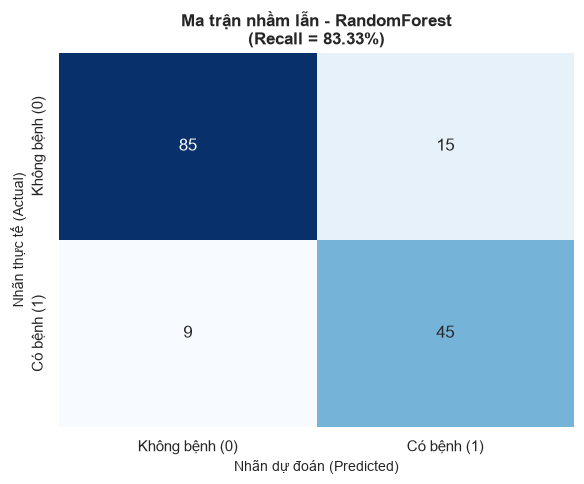

-> Đã xuất biểu đồ ra file: 'reports/confusion_matrix.png'


In [12]:
y_pred_best = best_model.predict(X_test_scaled)
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Không bệnh (0)', 'Có bệnh (1)'],
            yticklabels=['Không bệnh (0)', 'Có bệnh (1)'])

plt.title(f'Ma trận nhầm lẫn - {best_name}\n(Recall = {best_recall:.2%})', fontsize=12, fontweight='bold')
plt.xlabel('Nhãn dự đoán (Predicted)', fontsize=10)
plt.ylabel('Nhãn thực tế (Actual)', fontsize=10)
plt.tight_layout()

# Lưu ảnh biểu đồ phục vụ chèn Slide / Báo cáo
os.makedirs('../reports', exist_ok=True)
plt.savefig('../reports/confusion_matrix.png', dpi=300)
plt.show()
print(f"-> Đã xuất biểu đồ ra file: 'reports/confusion_matrix.png'")

In [13]:
os.makedirs('../mo_hinh', exist_ok=True)

payload = {
    'mo_hinh': best_model,
    'bo_chuan_hoa': scaler,
    'ten_dac_trung': list(X.columns)
}

output_pkl = '../mo_hinh/best_diabetes_model.pkl'
joblib.dump(payload, output_pkl)
print(f"🏆 Đã đóng gói thành công mô hình xuất sắc nhất ({best_name}) vào file: '{output_pkl}'")

🏆 Đã đóng gói thành công mô hình xuất sắc nhất (RandomForest) vào file: '../mo_hinh/best_diabetes_model.pkl'
